In [3]:
import os
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

%env DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"

env: DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"


In [7]:
import numpy as np
import tensorflow as tf

import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt

# Other imports
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy import constants

no_preview = False # Toggle to False to use the preview widget
import mitsuba as mi
# mi.set_variant("cuda_rgb")
# Import relevant components from Sionna RT
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies, LambertianPattern

import gc
import pickle

In [8]:
import inspect
import sionna.rt.path_solvers.sb_candidate_generator as sb
print(inspect.getfile(sb))


/path/to/sionna-venv/lib/python3.12/site-packages/sionna/rt/path_solvers/sb_candidate_generator.py


In [4]:
def is_point_free(scene, p, eps=1e-4):
    """
    scene : Sionna RT Scene
    p     : (3,) numpy array
    eps   : small offset distance
    """
    # for shape in scene._scene.shapes():
    #     bbox = shape.bbox()
    #     if bbox.contains(mi.Point3f(p)):
    #         return False
    # return True

    mi_scene = scene._scene  # Mitsuba scene

    # Fire rays in several directions
    directions = [
        [1,0,0], [-1,0,0],
        [0,1,0], [0,-1,0],
        [0,0,1], [0,0,-1],
    ]

    for d in directions:
        ray = mi.Ray3f(
            o=mi.Point3f(p),
            d=mi.Vector3f(d),
            time=0.0
        )
        si = mi_scene.ray_intersect(ray)
        if si.is_valid() and si.t < eps:
            return False  # point is inside or colliding

    return True


In [5]:
print(tf.config.list_physical_devices())
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# Import Scene

In [6]:
f = 11.7e9  # 11 GHz

eps_l = 3.1686 + 28.938/(1+1j*(f/18))-1j*(0.5672/f)
epsilon_0 = constants.epsilon_0
con = max(0,np.imag(eps_l)*2*np.pi*f*epsilon_0)


sionna.rt.radio_materials.itu.ITU_MATERIALS_PROPERTIES["tree"] = {
    (1.0, 100.0): (np.real(eps_l), 0.0, con, 0.0)  # (a, b, c, d) where εr=a*f^b, σ=c*f^d
}

sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["tree"] = (
    0.2, 0.6, 0.2,  # Green color
)

In [7]:
# need to define materials on 10-12 GHz for ku band

sionna.rt.radio_materials.itu.ITU_MATERIALS_PROPERTIES["medium_dry_ground"] = {
    (1.0, 13.0): (15, -0.1, 0.035, 1.63)  # (a, b, c, d) where εr=a*f^b, σ=c*f^d
}


sionna.rt.radio_materials.itu.ITU_MATERIALS_PROPERTIES["wet_ground"] = {
    (1.0, 13.0): (30, -0.4, 0.15, 1.3)  # (a, b, c, d) where εr=a*f^b, σ=c*f^d
}

# Change colors for visualization
sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["metal"] = (
    0.1, 0.1, 0.1,  # Dark Gray color
)

sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["concrete"] = (
    0.6, 0.5, 0.3,  # Beige color
)

sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["medium_dry_ground"] = (
    0.7, 0.7, 0.7,  # Light Gray color
)
sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["wet_ground"] = (
    0.0, 0.1, 0.6,  # Blue color
)

# Terrestrial Beaming Bench(Should be less rays)

In [8]:
import gc

In [23]:
scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
# scene.preview()

scene.frequency = f  # 11.7 GHz (Ku-band downlink)

# Instantiate Transmitter and reciever
scene.tx_array = PlanarArray(
    num_rows=8, # of rows
    num_cols=8, # of columns
    vertical_spacing=0.5, # in wavelengths
    horizontal_spacing=0.5, # in wavelengths
    pattern="tr38901", # Antenna pattern
    polarization="V" # Vertical polarization
)

terr_pos = [91.46426071, -120.132, 70.]  
rx_pos = [150.73967959, -207.83188, 10. ] # Receiver position

tx = Transmitter(
    name="sat_tx",
    position=terr_pos
    # orientation=[0.0, -np.pi/2, 0.0],  # Pointing down
)
scene.add(tx)

tx.power_dbm = 43 # Transmit power in dBm

# need to figure this out
scene.rx_array = PlanarArray(
    num_cols=1, 
    num_rows=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V")


rx = Receiver(
        name=f"ue_1",
        position= rx_pos,
        orientation=[0.0, 0.0, 0.0])
scene.add(rx)  

tx.look_at(rx_pos)  # Pointing to the center of the scene
num_samples = (2**32 - 1)// 64
# print(num_samples)

for name in ["paths_beam", "paths", "amp", "tau", "paths_buffer", "paths_iso" ]:
    if name in globals():
        del globals()[name]

gc.collect()
drjit.flush_malloc_cache()
drjit.eval()


p_solver  = PathSolver()
# Compute propagation paths
seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
paths_beam = p_solver(scene=scene,
                    max_depth=5,
                    los=True,
                    specular_reflection=True,
                    diffuse_reflection=True,
                    refraction=False,
                    diffraction=False,
                    synthetic_array=False,
                    max_num_paths_per_src=100_000,
                    samples_per_src=num_samples,
                    seed=seed,
                    beamforming=True,
                    beam_angle=0.8)
amp, tau = paths_beam.cir(normalize_delays=False, out_type="numpy")

t_beamed = tau[0,0,0,0,:]/1e-9 # Scale to ns
amp_beamed = np.abs(amp)[0,0,0,0,:,0]
# # Compute propagation paths
# seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
# paths_iso = p_solver(scene=scene,
#                     max_depth=5,
#                     los=True,
#                     specular_reflection=True,
#                     diffuse_reflection=True,
#                     refraction=False,
#                     diffraction=False,
#                     synthetic_array=False,
#                     max_num_paths_per_src=100_000,
#                     samples_per_src=num_samples,
#                     seed=seed)
# amp, tau = paths_iso.cir(normalize_delays=False, out_type="numpy")

# t_iso = tau[0,0,0,0,:]/1e-9 # Scale to ns
# amp_iso = np.abs(amp)[0,0,0,0,:,0]

In [24]:
print(len(amp_beamed))

5


# Verification

In [117]:
print(len(t_iso), len(t_beamed))
# print(amp_beamed)
# print(amp_iso)
print(tx.orientation)

11 5
[[-0.976436, 0.515668, 0]]


In [118]:
def boresight_from_alpha_beta(alpha, beta, gamma=0.0):
    # alpha, beta, gamma in radians (Sionna convention)
    ca, sa = np.cos(alpha), np.sin(alpha)
    cb, sb = np.cos(beta),  np.sin(beta)
    cg, sg = np.cos(gamma), np.sin(gamma)

    # R = Rz(alpha) * Ry(beta) * Rx(gamma)
    Rz = np.array([[ca, -sa, 0.0],
                   [sa,  ca, 0.0],
                   [0.0, 0.0, 1.0]])

    Ry = np.array([[ cb, 0.0, sb],
                   [0.0, 1.0, 0.0],
                   [-sb, 0.0, cb]])

    Rx = np.array([[1.0, 0.0, 0.0],
                   [0.0,  cg, -sg],
                   [0.0,  sg,  cg]])

    R = Rz @ Ry @ Rx

    # IMPORTANT: boresight is +x in your sampling convention
    bore = R @ np.array([1.0, 0.0, 0.0])

    return bore / np.linalg.norm(bore)


def in_cone(bore, tx_pos, V, beam_angle):
    bore = np.asarray(bore, dtype=np.float64)
    
    rx, tx = 0,0
    
    # Tx point and first interaction point for every path
    v0 = V[0, rx, 0, tx, 0, :, :]   # (P,3)
    
    
    # AoD direction unit vector for every path (world coordinates)
    k_tx = v0 - tx_pos
    k_tx /= np.linalg.norm(k_tx, axis=-1, keepdims=True)
    
    for i in range(len(k_tx)):

        c = np.clip(np.dot(k_tx[i], bore), -1.0, 1.0)
        theta = np.arccos(c)
        print(theta <= beam_angle)

In [124]:
alpha, beta = tx.orientation[0][0], tx.orientation[1][0]
# print(alpha, beta)
boresight = boresight_from_alpha_beta(float(alpha), float(beta))

V = paths_beam.vertices.numpy()


# print(V[0,0,0,0,0,:,:])
in_cone(boresight, terr_pos, V, 0.8)

# First is LoS

False
True
True
True
True


In [120]:
# idx =[5,6]
# mask = tf.zeros_like(paths_beam.a)
# mask = tf.tensor_scatter_nd_update(
#     mask,
#     indices=[[0,0,0,i] for i in idx],
#     updates=tf.gather(paths_beam.a[0,0,0,:], idx)
# )

# paths_beam.a = mask

print(t_beamed) 
print(amp_beamed)


[405.8647  442.60336 620.53687 490.07022 457.1622 ]
[4.2094249e-05 7.3111933e-06 4.1205817e-07 2.3841969e-06 1.6734883e-05]


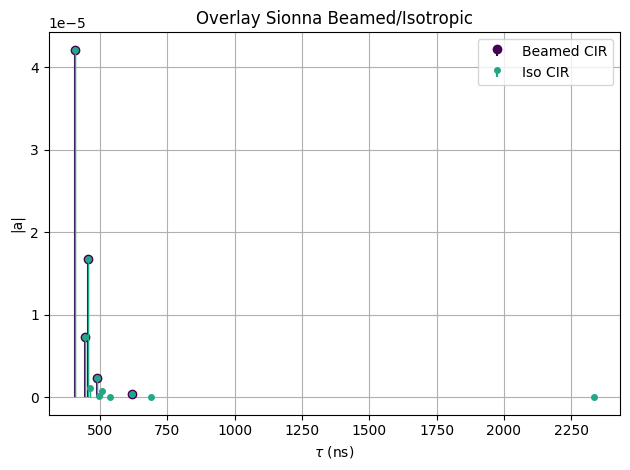

In [121]:
cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, 6))


markerline, stemlines, baseline = plt.stem(t_beamed, amp_beamed,basefmt=" ")

# Color configuration
plt.title(f"Overlay Sionna Beamed/Isotropic")
plt.setp(markerline, color=C[0], markersize=6)
plt.setp(stemlines, color=C[0], linewidth=1.5)

valid_idx = np.where(t_iso >= 0)

markerline, stemlines, baseline = plt.stem(t_iso[valid_idx], amp_iso[valid_idx],basefmt=" ")


plt.setp(markerline, color=C[3], markersize=4)
plt.setp(stemlines, color=C[3], linewidth=1.0)

plt.grid()
plt.ylabel(r"|a|")
plt.xlabel(r"$\tau$ (ns)")

# plt.xlim(800, 1200)

plt.legend(['Beamed CIR', 'Iso CIR'])
plt.tight_layout()
plt.show()

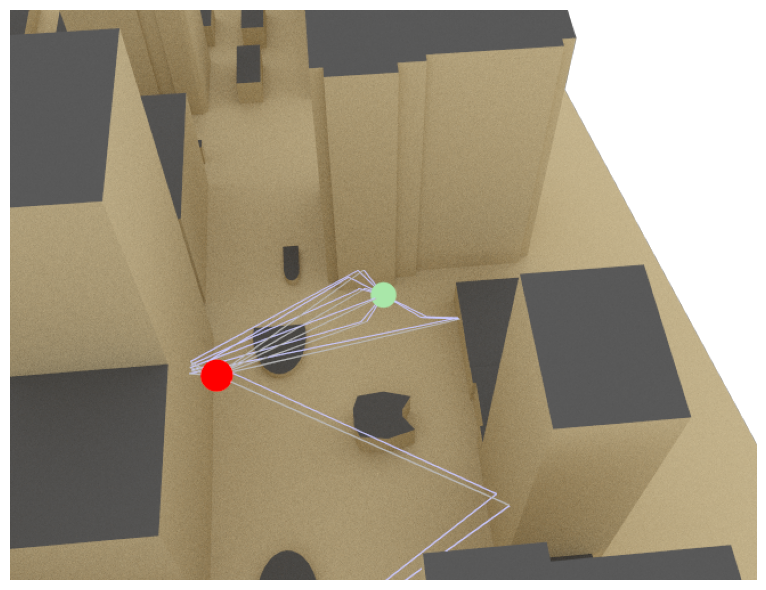

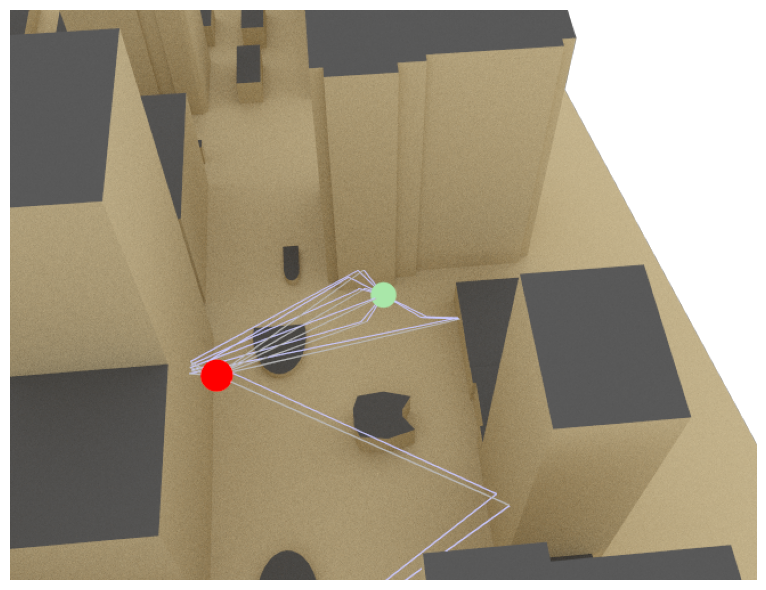

In [126]:
bird_cam = Camera(position=[-100,-140,400], look_at=rx_pos)
scene.render(camera=bird_cam, paths=paths_iso)

# NTN Beaming Test

In [21]:
baseline_tx_pos = [22e3, 35e3, 550e3]
rx_pos = [300, 25, 100. ] # Receiver position

direct = np.asarray(baseline_tx_pos) - np.asarray(rx_pos)
direct = direct/np.linalg.norm(direct)
d = 1000 # distance in meters

new_tx_pos = rx_pos + d*direct
print(new_tx_pos)

scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
# scene.preview()

scene.frequency = f  # 11.7 GHz (Ku-band downlink)

# Instantiate Transmitter and reciever
# need to figure this out
scene.tx_array = PlanarArray(
    num_rows=8, # of rows
    num_cols=8, # of columns
    vertical_spacing=0.5, # in wavelengths
    horizontal_spacing=0.5, # in wavelengths
    pattern="tr38901", # Antenna pattern
    polarization="V" # Vertical polarization
)


tx = Transmitter(
    name="sat_tx",
    position=new_tx_pos
    # orientation=[0.0, -np.pi/2, 0.0],  # Pointing down
)
scene.add(tx)

tx.power_dbm = 50 # Transmit power in dBm

# need to figure this out
scene.rx_array = PlanarArray(
    num_cols=1, 
    num_rows=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V")


rx = Receiver(
        name=f"ue_1",
        position= rx_pos,
        orientation=[0.0, 0.0, 0.0])
scene.add(rx)  

tx.look_at(rx_pos)  # Pointing to the center of the scene
num_samples = (2**32 - 1) //64
# print(num_samples)


for name in ["paths_beam", "paths", "amp", "tau", "paths_buffer", "paths_iso",  ]:
    if name in globals():
        del globals()[name]

gc.collect()
drjit.flush_malloc_cache()
drjit.eval()

# for i in range(50):
p_solver  = PathSolver()
    # Compute propagation paths
seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
paths_beam = p_solver(scene=scene,
                    max_depth=5,
                    los=True,
                    specular_reflection=True,
                    diffuse_reflection=True,
                    refraction=False,
                    diffraction=True,
                    synthetic_array=False,
                    max_num_paths_per_src=50_000,
                    samples_per_src=num_samples,
                    seed=seed,
                    beamforming=True,
                    beam_angle=0.05)
amp, tau = paths_beam.cir(normalize_delays=False, out_type="numpy")

t_beam = tau[0,0,0,0,:]/1e-9 # Scale to ns
amp_beam = np.abs(amp)[0,0,0,0,:,0]

# seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
# paths_iso = p_solver(scene=scene,
#                     max_depth=5,
#                     los=True,
#                     specular_reflection=True,
#                     diffuse_reflection=True,
#                     refraction=False,
#                     diffraction=False,
#                     synthetic_array=False,
#                     max_num_paths_per_src=50_000,
#                     samples_per_src=num_samples,
#                     seed=seed)
# amp, tau = paths_iso.cir(normalize_delays=False, out_type="numpy")

# t_iso = tau[0,0,0,0,:]/1e-9 # Scale to ns
# amp_iso = np.abs(amp)[0,0,0,0,:,0]

[ 339.35164046   88.42505184 1097.21046484]


In [22]:
print( len(amp_beam))

3


In [18]:
bird_cam = Camera(position=[350,500,700], look_at=rx_pos)
scene.render(camera=bird_cam, paths=paths)

NameError: name 'paths' is not defined

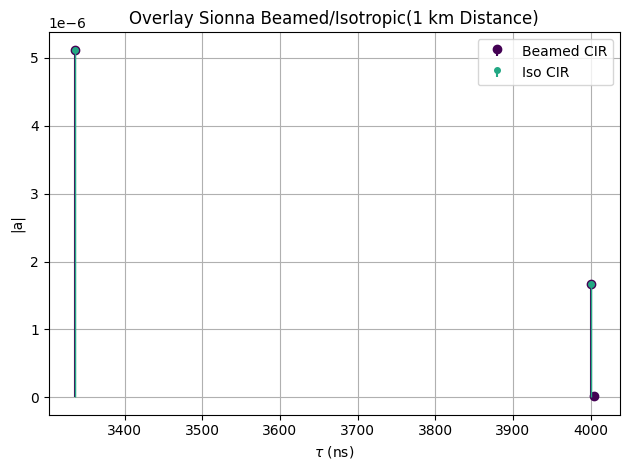

In [139]:
cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, 6))


markerline, stemlines, baseline = plt.stem(t_beam, amp_beam,basefmt=" ")

# Color configuration
plt.title(f"Overlay Sionna Beamed/Isotropic(1 km Distance)")
plt.setp(markerline, color=C[0], markersize=6)
plt.setp(stemlines, color=C[0], linewidth=1.5)

markerline, stemlines, baseline = plt.stem(t_iso, amp_iso,basefmt=" ")


plt.setp(markerline, color=C[3], markersize=4)
plt.setp(stemlines, color=C[3], linewidth=1.0)

plt.grid()
plt.ylabel(r"|a|")
plt.xlabel(r"$\tau$ (ns)")

# plt.xlim(800, 1200)

plt.legend(['Beamed CIR', 'Iso CIR'])
plt.tight_layout()
plt.show()

In [17]:
sat_tx_pos = [22e3, 35e3, 550e3]
rx_pos = [200, 200, 50] # Receiver position
direct = np.asarray(sat_tx_pos) - np.asarray(rx_pos)
direct = direct/np.linalg.norm(direct)

a = 1000
new_tx_pos = rx_pos + a*direct
print(new_tx_pos)

[ 239.52992105  263.10280975 1047.22385689]


In [126]:
sat_tx_pos = [22e3, 35e3, 550e3]
rx_pos = [300, 50, 100] # Receiver position
direct = np.asarray(sat_tx_pos) - np.asarray(rx_pos)
direct = direct/np.linalg.norm(direct)

a = [20, 50, 100, 200, 500, 1000]

# print(new_tx_pos)

CIRs =[]

for d in a:
    scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
    # scene.preview()

    scene.frequency = f  # 11.7 GHz (Ku-band downlink)

    # Instantiate Transmitter and reciever
    # need to figure this out
    scene.tx_array = PlanarArray(
        num_rows=8, # of rows
        num_cols=8, # of columns
        vertical_spacing=0.5, # in wavelengths
        horizontal_spacing=0.5, # in wavelengths
        pattern="tr38901", # Antenna pattern
        polarization="V" # Vertical polarization
    )
    new_tx_pos = rx_pos + d*direct

    tx = Transmitter(
        name="sat_tx",
        position=new_tx_pos
        # orientation=[0.0, -np.pi/2, 0.0],  # Pointing down
    )
    scene.add(tx)

    tx.power_dbm = 43 # Transmit power in dBm

    # need to figure this out
    scene.rx_array = PlanarArray(
        num_cols=1, 
        num_rows=1,
        vertical_spacing=0.5,
        horizontal_spacing=0.5,
        pattern="iso",
        polarization="V")


    rx = Receiver(
            name=f"ue_1",
            position= rx_pos,
            orientation=[0.0, 0.0, 0.0])
    scene.add(rx)  

    tx.look_at(rx_pos)  # Pointing to the center of the scene
    num_samples = (2**32 - 1) //64
    # print(num_samples)
    
    # for i in range(50):
    p_solver  = PathSolver()
        # Compute propagation paths
    seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
    paths = p_solver(scene=scene,
                        max_depth=5,
                        los=True,
                        specular_reflection=True,
                        diffuse_reflection=True,
                        refraction=True,
                        diffraction=False,
                        synthetic_array=False,
                        max_num_paths_per_src=100_000,
                        samples_per_src=num_samples,
                        seed=seed)
    a, tau = paths.cir(normalize_delays=False, out_type="numpy")

    t = tau[0,0,0,0,:]/1e-9 # Scale to ns
    a_abs = np.abs(a)[0,0,0,0,:,0]
    
    CIRs.append((t, a_abs))

86


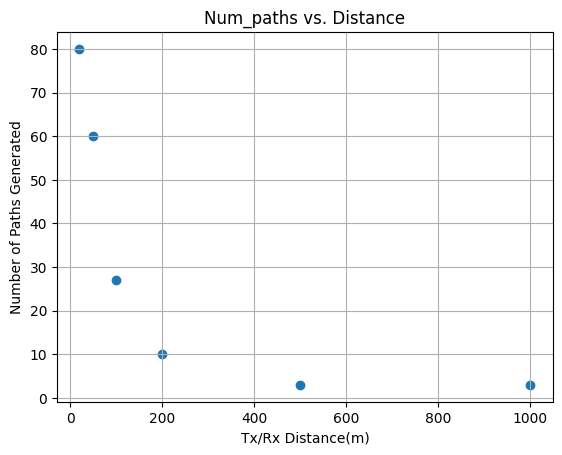

In [127]:
# shape: [max_depth, num_rx, num_tx, num_paths, 3]
# vertices = paths.vertices
    
# # Extract vertices for specific path
# path_vertices = vertices[:, 0, 0, 0, 0, :, :]

# print(path_vertices)

# num_paths = paths.a[0][0,0,0,0,:]
# print(num_paths.shape)
# a, tau = paths.cir(normalize_delays=False, out_type="numpy")

# t = tau[0,0,0,0,:]/1e-9 # Scale to ns
# a_abs = np.abs(a)[0,0,0,0,:,0]
# print(a_abs)

# print(num_paths[0][0])

cir = CIRs[0]
print(len(cir[1]))
lens = []
for cir in CIRs:
    nz = np.where(cir[1] > 0)
    lens.append(len(cir[1][nz]))
    
a = [20, 50, 100, 200, 500, 1000]
plt.scatter(a, lens)
# plt.semilogx()
# plt.xlim(0, 1000)
plt.xlabel("Tx/Rx Distance(m)")
plt.ylabel("Number of Paths Generated")
plt.title("Num_paths vs. Distance")
plt.grid()

# Test 1: rx_pos = 200, 200, 50
# distance = 25m num paths = 
# distance = 100m num paths = 18
# distance = 1km num paths = 3
# distance = 10 km num paths = 3

# Test 2: rx_pos = -200, -200, 50
# distance = 100m num paths =35
# distance = 1 km num paths = 2


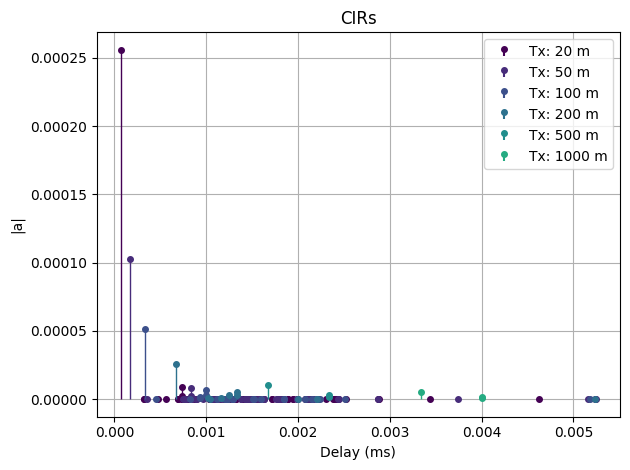

In [128]:
plt.figure()

cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, len(a)))

for i in range(len(a)):
    t, a_abs = CIRs[i]
    nonzero = np.where(a_abs > 0)
    markerline, stemlines, baseline = plt.stem(t[nonzero]*10**-6, a_abs[nonzero],basefmt=" ", label=f"Tx: {a[i]} m")

    # Color configuration
 
    plt.setp(markerline, color=C[i], markersize=4)
    plt.setp(stemlines, color=C[i], linewidth=1.0)

plt.grid()
plt.title("CIRs")
plt.xlabel(f"Delay (ms)")
plt.ylabel("|a|")
# plt.xlim(0, .03)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# CIR: List of CIRs generated, 
# each CIR is a tuple of lists: taus and a_abs, which each contains sublists 
# where each path is stored according to on the sublist according to its corresponding Rx

# Rx_catalog: List containing sublists, each sublists stores the position of the receiver
verts = []
CIR = []
Rx_catalog = []
for n in range(5):
    scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
    scene.frequency = f  # 11.7 GHz (Ku-band downlink)
    
    # Instantiate Transmitter and reciever
    # need to figure this out
    scene.tx_array = PlanarArray(
        num_rows=8, # of rows
        num_cols=8, # of columns
        vertical_spacing=0.5, # in wavelengths
        horizontal_spacing=0.5, # in wavelengths
        pattern="tr38901", # Antenna pattern
        polarization="V" # Vertical polarization
    )



    tx_pos = [1e3, 10e3, 550e3] # Transmitter position
    tx = Transmitter(
        name="sat_tx",
        position=tx_pos
        # orientation=[0.0, -np.pi/2, 0.0],  # Pointing down
    )
    scene.add(tx)

    tx.power_dbm = 43 # Transmit power in dBm

    # need to figure this out
    scene.rx_array = PlanarArray(
        num_cols=1, 
        num_rows=1,
        vertical_spacing=0.5,
        horizontal_spacing=0.5,
        pattern="iso",
        polarization="V")


    tx.look_at([0, 0, 0])  # Pointing to the center of the scene
    
    
    """randomize receiver position logic
    """
    temp_rx_cat = []
    for i in range(10):
        x = np.random.uniform(-300, 300)
        y = np.random.uniform(-300, 300)
        z = np.random.uniform(20, 150)
        
        rx_pos = [x, y, z] # Receiver position
        
        
        while not is_point_free(scene, np.array(rx_pos), eps=1e-4):
            x = np.random.uniform(-300, 300)
            y = np.random.uniform(-300, 300)
            z = np.random.uniform(20, 150)
            rx_pos = [x, y, z]
            
        
        rx = Receiver(
            name=f"ue_{i + 1}",
            position= rx_pos,
            orientation=[0.0, 0.0, 0.0]  # Pointing up
            )
        scene.add(rx)
        temp_rx_cat.append(rx_pos)
#         rx_names = list(scene.receivers.keys())
        
       
    p_solver  = PathSolver()
    seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
    # Compute propagation paths
    paths = p_solver(scene=scene,
                    max_depth=3,
                    los=True,
                    specular_reflection=True,
                    diffuse_reflection=True,
                    refraction=True,
                    diffraction=False,
                    synthetic_array=False,
                    max_num_paths_per_src=50_000,
                    samples_per_src=100_000_000,
                    seed=seed)


    a, tau = paths.cir(normalize_delays=False, out_type="numpy")
    vertices = paths.vertices.numpy()
    
    t_temp = []
    a_temp = []
    
    for n in range(tau.shape[0]):
        rec = tau[n,0,0,0,:]
        loop_t = []
        loop_a = []
        for i, tap in enumerate(rec):
            if not np.isclose(tap, -1):
                loop_t.append(tap/1e-6) # Scale to ms
                loop_a.append(np.abs(a)[n,0,0,0,i,0])
        t_temp.append(loop_t)
        a_temp.append(loop_a)
    verts.append(vertices)
    CIR.append((t_temp, a_temp))
    Rx_catalog.append(temp_rx_cat)


In [34]:
# print(len(verts))

CIR1 = CIR[2]
t, a_abs = CIR1
print(t)

[[1834.618509747088], [1834.7091972827911, 1835.0727623328567], [1834.5974385738373], [1834.4379495829344], [], [1834.480557590723], [1834.5017451792955], [1834.6915021538734], [1834.52561032027], [1834.4494746997952]]


In [38]:
Rx_cat = Rx_catalog[2]
print(Rx_cat[0])

[-92.76134717127286, -113.86264228837803, 89.24349135707597]


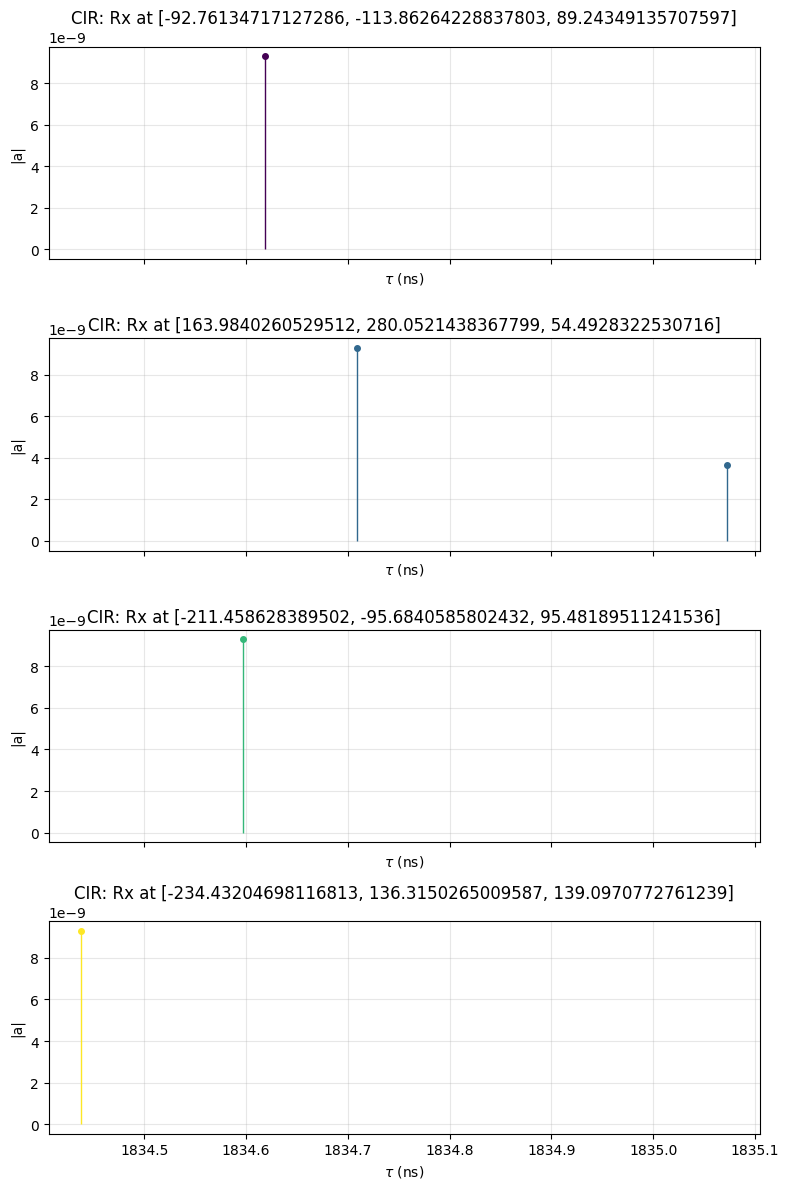

In [39]:
num = 4

cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, num))

fig, axes = plt.subplots(
    nrows=num,
    ncols=1,
    figsize=(8, 12),
    sharex=True
)
cir = CIR[2]
rxs = Rx_catalog[2]
for i, ax in enumerate(axes):
    
    t, a_abs = cir
    markerline, stemlines, baseline = ax.stem(t[i], a_abs[i],basefmt=" ")
    rx_pos = rxs[i]
    # Color configuration
    ax.set_title(f"CIR: Rx at {rx_pos}")
    plt.setp(markerline, color=C[i], markersize=4)
    plt.setp(stemlines, color=C[i], linewidth=1.0)

    ax.grid(True, alpha=0.3)
    ax.set_ylabel(r"|a|")
    ax.set_xlabel(r"$\tau$ (ns)")

# plt.xlim(600, 800)
plt.tight_layout()
plt.show()

In [21]:
print(t[9], aa[9])

[1835058.443248272, 1834731.549024582] [3.648912e-09, 9.308043e-09]


In [34]:
sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["concrete"] = (
    0.6, 0.5, 0.3,  # Beige color
)

In [50]:
f= 11.7e9
lambda_c = 3e8 / f

# small local area (~few wavelengths)
d = lambda_c * 2

rx_pos = [0 + np.random.uniform(-d, d),
          0 + np.random.uniform(-d, d),
          0.5]

# Set concrete scattering properties
scene = load_scene("./flat_plane/plain.xml", merge_shapes=False)
scene.frequency = f  # 11.7 GHz (Ku-band downlink)
mat = scene.get("itu_concrete")
mat.scattering_coefficient = 0.6
mat.scattering_pattern = LambertianPattern()



# Create Transmitter Array
scene.tx_array = PlanarArray(
    num_rows=1, # of rows
    num_cols=1, # of columns
    vertical_spacing=0.5, # in wavelengths
    horizontal_spacing=0.5, # in wavelengths
    pattern="iso", # Antenna pattern
    polarization="V" # Vertical polarization
    )

# Create Receiver Array
scene.rx_array = PlanarArray(
    num_cols=1, 
    num_rows=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V")


tx_pos = [100, 0, 10]
tx = Transmitter(
    name="tx_1",
    position=tx_pos
)
scene.add(tx)

tx.power_dbm = 43 # Transmit power in dBm

rx = Receiver(
        name=f"ue_1",
        position= rx_pos,
        orientation=[0.0, 0.0, 0.0])
scene.add(rx)  

tx.look_at(rx_pos)  # Pointing to the center of the scene
angle = np.arctan(50/np.linalg.norm(tx_pos))


p_solver  = PathSolver()

# Compute propagation paths
seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
paths = p_solver(scene=scene,
                    max_depth=1,
                    los=True,
                    specular_reflection=False,
                    diffuse_reflection=True,
                    refraction=False,
                    diffraction=False,
                    synthetic_array=False,
                    max_num_paths_per_src=50,
                    samples_per_src=1_000_000,
                    seed=seed,
                    beamforming=True,
                    beam_angle=angle)

a_vis, t_vis = paths.cir(normalize_delays=False, out_type="numpy")

In [51]:
print(t_vis[0][0][0][0])

[7.8783228e-07 3.6009479e-07 3.4726264e-07 4.1514494e-07 3.5263628e-07
 2.3557923e-06 3.6928790e-07 3.4879329e-07 5.4632284e-07 3.5656069e-07
 3.4651677e-07 3.8873398e-07 3.5090136e-07 1.0860385e-06 3.6294873e-07
 3.4779279e-07 4.4525152e-07 3.5393762e-07 3.3495860e-07 1.5636184e-06
 3.6504588e-07 3.4787774e-07 4.8617926e-07 3.5459274e-07 3.4604759e-07
 3.7995844e-07 3.4972643e-07 8.4778162e-07 3.5991928e-07 3.4699389e-07
 4.1931295e-07 3.5235485e-07 2.8301006e-06 3.6942717e-07 3.4851266e-07
 5.6986534e-07 3.5631791e-07 3.4625651e-07 3.9014222e-07 3.6230966e-07
 3.4747072e-07 4.4476167e-07 3.5346912e-07 3.7405499e-07 3.4914871e-07
 6.7535501e-07 3.5804482e-07 3.4666155e-07 3.7926398e-07 3.5001170e-07]


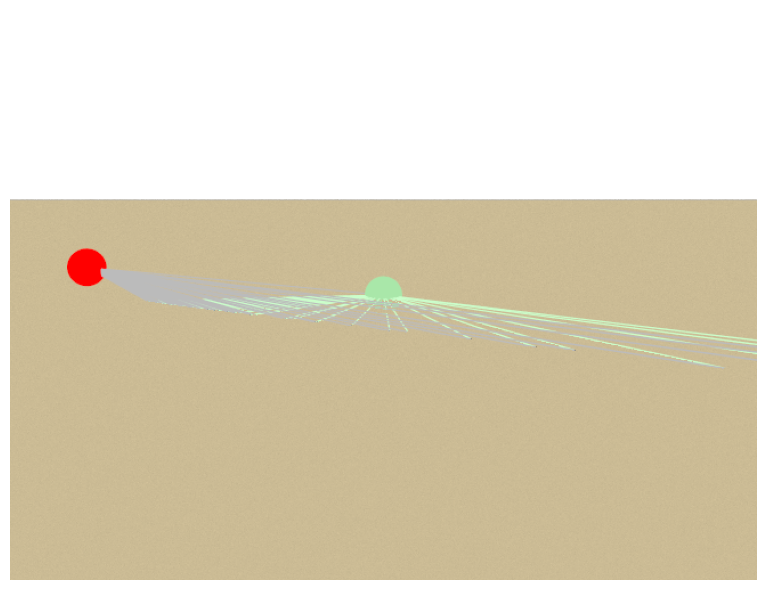

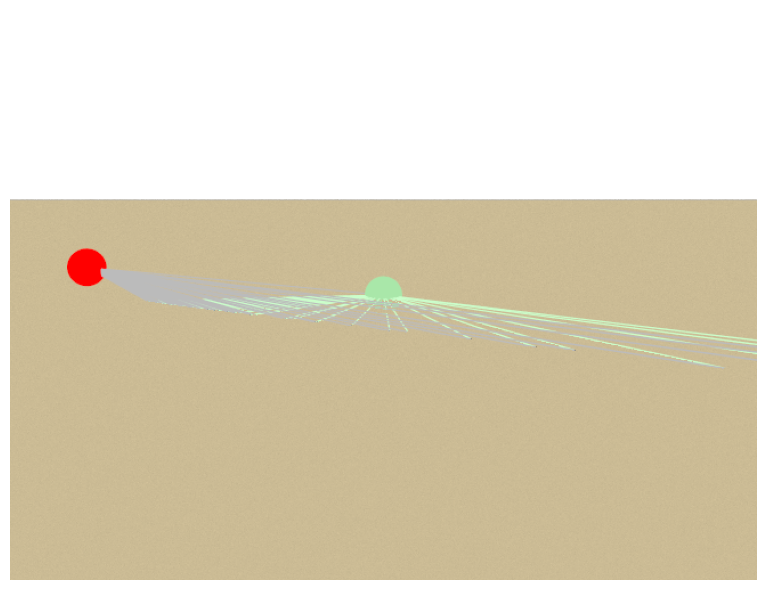

In [53]:
bird_cam = Camera(position=[0,300, 60], look_at=rx_pos)
scene.render(camera=bird_cam, paths = paths)